In [ ]:
!pip -q install catboost
!pip -q install xgboost
!pip -q install lightgbm

In [ ]:
import pandas as pd
import numpy as np
from scipy import stats
from sklearn.metrics import mean_squared_error

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.compose import make_column_transformer, ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder, StandardScaler, OneHotEncoder

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, VotingRegressor, StackingRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
import lightgbm as lgb

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score
from sklearn.ensemble import HistGradientBoostingClassifier

In [ ]:
df = pd.read_csv('/content/winequality-red.csv')

In [ ]:
df.columns

Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality'],
      dtype='object')

In [ ]:
df.describe( )

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


# **Analise Exploratória**

In [ ]:
pd.DataFrame(df.isnull().sum().sort_values(ascending=False)).head(28)

,0
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


In [ ]:
df.dtypes[df.dtypes != 'object']

,0
fixed acidity,float64
volatile acidity,float64
citric acid,float64
residual sugar,float64
chlorides,float64
free sulfur dioxide,float64
total sulfur dioxide,float64
density,float64
pH,float64
sulphates,float64


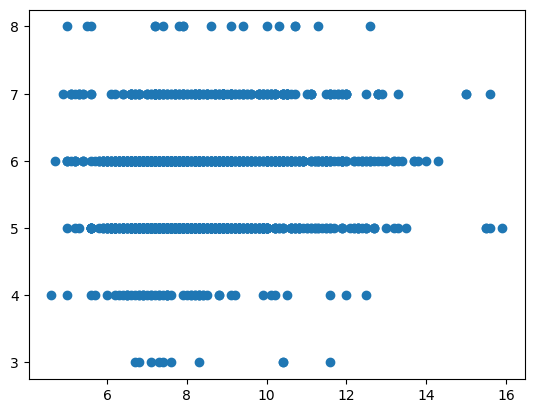

In [ ]:
plt.scatter(x='fixed acidity', y='quality', data=df)

In [ ]:
df.query('`fixed acidity` > 14')

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
243,15.0,0.210,0.44,2.2,0.075,10.0,24.0,1.00005,3.07,0.84,9.2,7
244,15.0,0.210,0.44,2.2,0.075,10.0,24.0,1.00005,3.07,0.84,9.2,7
442,15.6,0.685,0.76,3.7,0.100,6.0,43.0,1.00320,2.95,0.68,11.2,7
544,14.3,0.310,0.74,1.8,0.075,6.0,15.0,1.00080,2.86,0.79,8.4,6
554,15.5,0.645,0.49,4.2,0.095,10.0,23.0,1.00315,2.92,0.74,11.1,5
555,15.5,0.645,0.49,4.2,0.095,10.0,23.0,1.00315,2.92,0.74,11.1,5
557,15.6,0.645,0.49,4.2,0.095,10.0,23.0,1.00315,2.92,0.74,11.1,5
652,15.9,0.360,0.65,7.5,0.096,22.0,71.0,0.99760,2.98,0.84,14.9,5


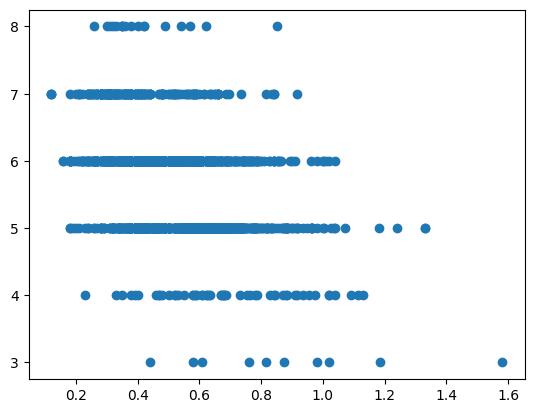

In [ ]:
plt.scatter(x='volatile acidity', y='quality', data=df)

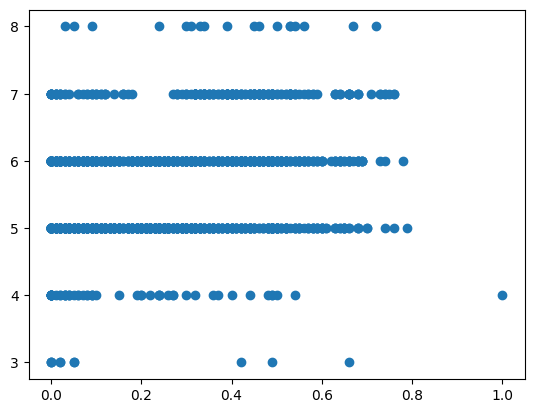

In [ ]:
plt.scatter(x='citric acid', y='quality', data=df)

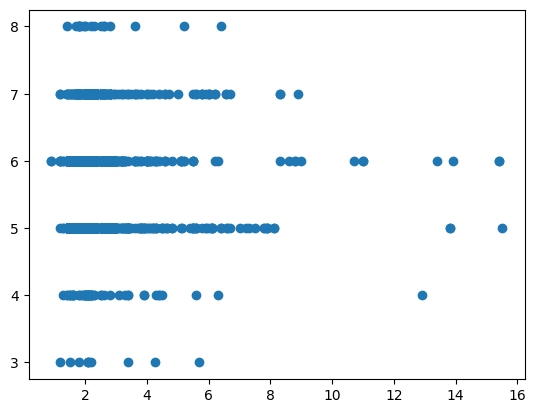

In [ ]:
plt.scatter(x='residual sugar', y='quality', data=df)

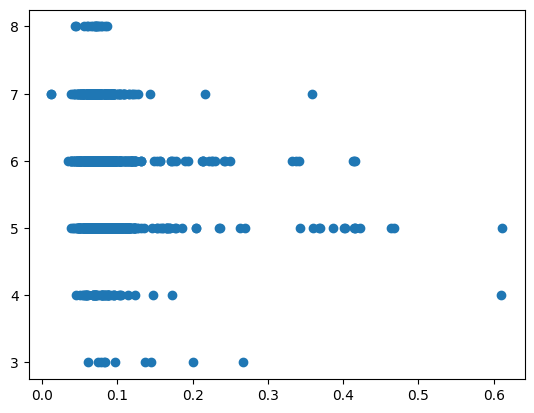

In [ ]:
plt.scatter(x='chlorides', y='quality', data=df)

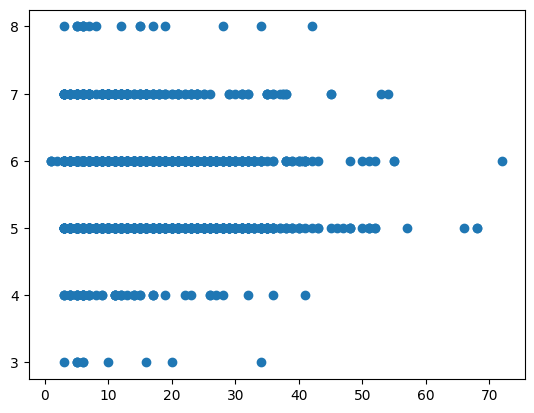

In [ ]:
plt.scatter(x='free sulfur dioxide', y='quality', data=df)

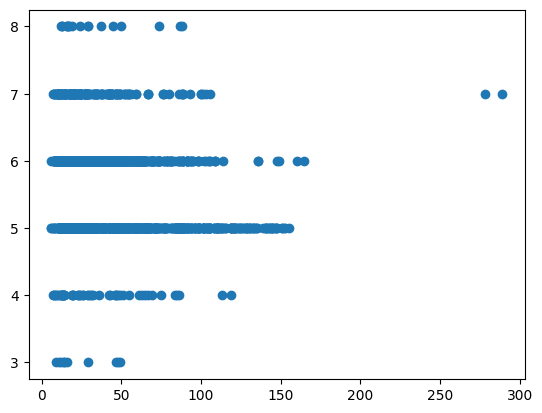

In [ ]:
plt.scatter(x='total sulfur dioxide', y='quality', data=df)

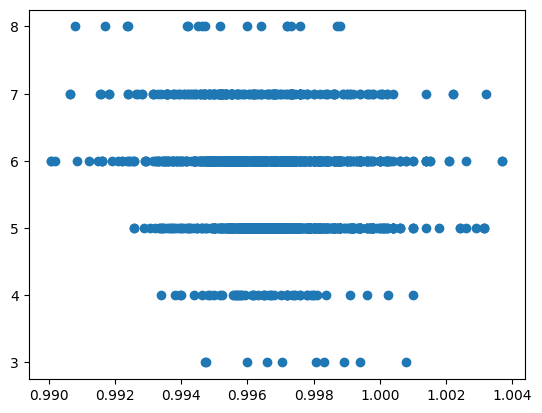

In [ ]:
plt.scatter(x='density', y='quality', data=df)

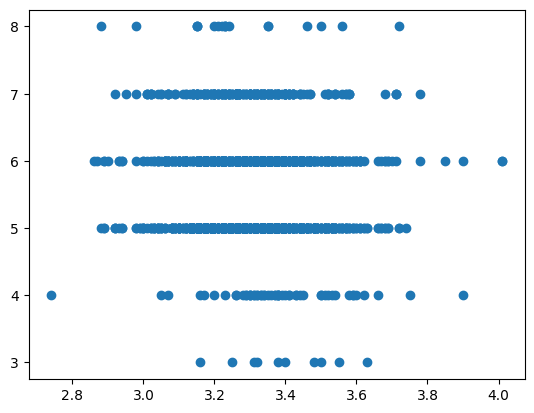

In [ ]:
plt.scatter(x='pH', y='quality', data=df)

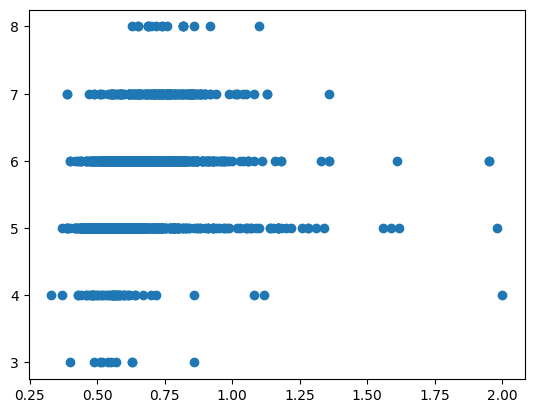

In [ ]:
plt.scatter(x='sulphates', y='quality', data=df)

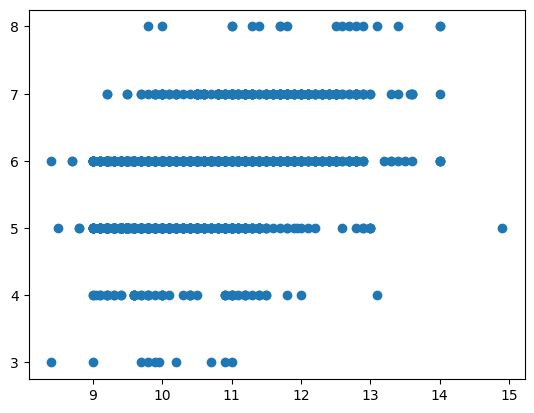

In [ ]:
plt.scatter(x='alcohol', y='quality', data=df)

# **Feature Engineering**

In [ ]:
df['sulfur_ratio'] = df['free sulfur dioxide']/df['total sulfur dioxide']

In [ ]:
df['acidity_balance'] = df['fixed acidity']/df['volatile acidity']

In [ ]:
df = df.drop(columns=['free sulfur dioxide','total sulfur dioxide','fixed acidity','volatile acidity'])

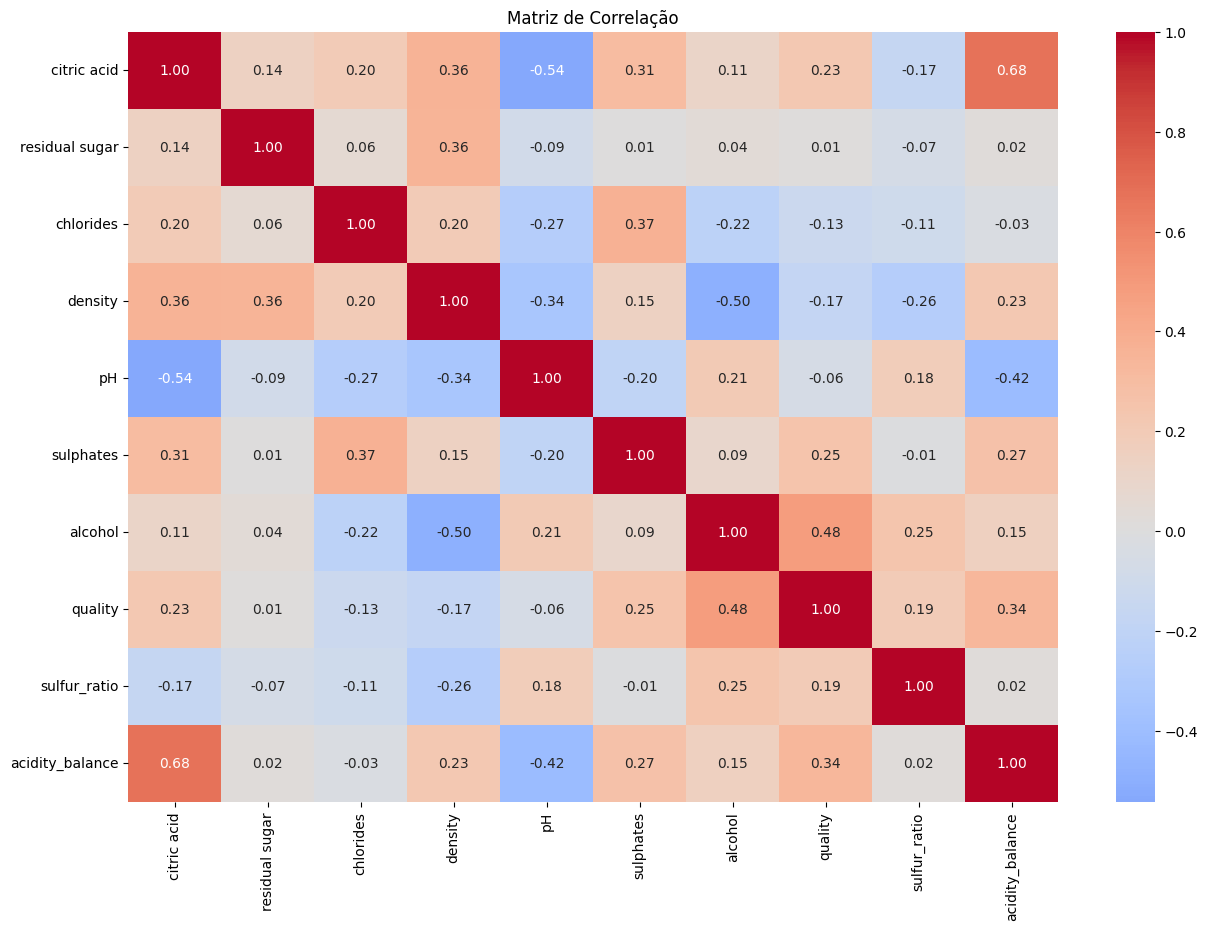

In [ ]:
correlation_matrix = df.corr(numeric_only=True)
plt.figure(figsize=(15,10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', center=0)
plt.title('Matriz de Correlação')
plt.show()

In [ ]:
df = df.drop(columns=['residual sugar','pH'])

<Axes: xlabel='quality', ylabel='Count'>

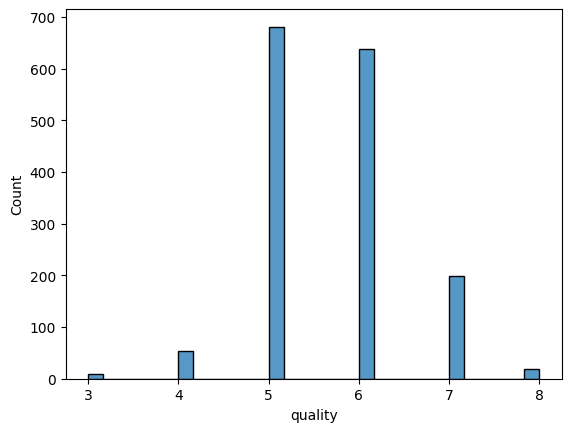

In [ ]:
sns.histplot(df, x=df['quality'])

In [ ]:
def agrupar(nota):
    if nota <= 4:
        return 'ruim'
    elif nota <= 6:
        return 'medio'
    else:
        return 'bom'

In [ ]:
df['quality_category'] = df['quality'].apply(agrupar)

<Axes: xlabel='quality_category', ylabel='count'>

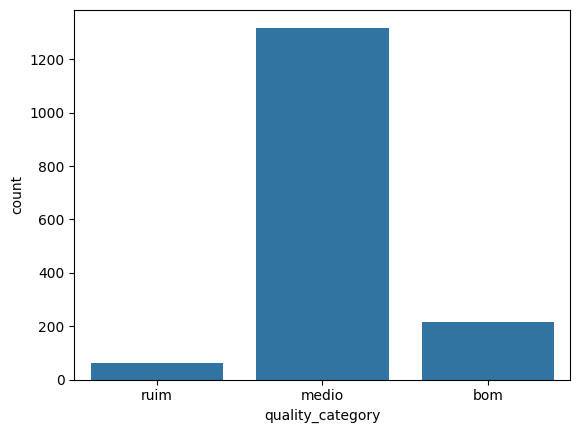

In [ ]:
sns.countplot(x='quality_category', data=df, order=['ruim', 'medio', 'bom'])

# **Pipeline**

In [ ]:
df.dtypes[df.dtypes != 'object']

,0
citric acid,float64
chlorides,float64
density,float64
sulphates,float64
alcohol,float64
quality,int64
sulfur_ratio,float64
acidity_balance,float64


In [ ]:
onh_enc = ['citric acid', 'chlorides', 'density', 'sulphates', 'alcohol', 'sulfur_ratio','acidity_balance']

In [ ]:
encoder = OrdinalEncoder(categories=[['ruim', 'medio', 'bom']])
y_encoded = encoder.fit_transform(df[['quality_category']])

In [ ]:
X = df.drop(['quality', 'quality_category'], axis=1)
y = df['quality_category']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.3,random_state=75)

In [ ]:
num_pipeline = Pipeline(steps=[('impute', SimpleImputer(strategy='mean')),
                               ('scale',RobustScaler()) ])

In [ ]:
col_trans = ColumnTransformer(
    transformers=[
        ('num_pipeline', num_pipeline, onh_enc),
    ],
    remainder='drop',
    n_jobs=-1
)


# **Treinamento**

**Random Forest**

In [ ]:
rf = RandomForestClassifier(random_state=42)

In [ ]:
pipefinal = make_pipeline(col_trans, rf)

In [ ]:
pipefinal.fit(X_train, y_train)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(n_jobs=-1,
                                   transformers=[('num_pipeline',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer()),
                                                                  ('scale',
                                                                   RobustScaler())]),
                                                  ['citric acid', 'chlorides',
                                                   'density', 'sulphates',
                                                   'alcohol', 'sulfur_ratio',
                                                   'acidity_balance'])])),
                ('randomforestclassifier',
                 RandomForestClassifier(random_state=42))])

In [ ]:
pipefinal.score(X_test, y_test)


0.8708333333333333

In [ ]:
y_pred = pipefinal.predict(X_test)
f1 = f1_score(y_test, y_pred, average='weighted')
print('F1-Score:', f1)


F1-Score: 0.8539139040783776


**Gradient Boosting**

In [ ]:
gbc = HistGradientBoostingClassifier(random_state=42)

In [ ]:
pipefinal1 = make_pipeline(col_trans, gbc)

In [ ]:
pipefinal1.fit(X_train, y_train)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(n_jobs=-1,
                                   transformers=[('num_pipeline',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer()),
                                                                  ('scale',
                                                                   RobustScaler())]),
                                                  ['citric acid', 'chlorides',
                                                   'density', 'sulphates',
                                                   'alcohol', 'sulfur_ratio',
                                                   'acidity_balance'])])),
                ('histgradientboostingclassifier',
                 HistGradientBoostingClassifier(random_state=42))])

In [ ]:
pipefinal1.score(X_test, y_test)

0.8791666666666667

In [ ]:
y_pred = pipefinal1.predict(X_test)
f1 = f1_score(y_test, y_pred, average='weighted')
print('F1-Score:', f1)

F1-Score: 0.8644558988617377
